In [1]:
!pip install ultralytics opencv-python matplotlib roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 77.7 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [roboflow]


In [2]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

GPU Available: False
Using CPU


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sayedgamal99/smoke-fire-detection-yolo")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'smoke-fire-detection-yolo' dataset.
Path to dataset files: /kaggle/input/smoke-fire-detection-yolo


In [4]:
import os

dataset_path = "/kaggle/input/smoke-fire-detection-yolo"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

smoke-fire-detection-yolo/
  data.yaml
  data/
    val/
      labels/
        PublicDataset01019.txt
        WEB08651.txt
        WEB07304.txt
        WEB07388.txt
        WEB02204.txt
      images/
        AoF04660.jpg
        WEB05194.jpg
        AoF04762.jpg
        WEB05365.jpg
        AoF03726.jpg
    test/
      labels/
        AoF08003.txt
        WEB09687.txt
        AoF07034.txt
        AoF07163.txt
        WEB10642.txt
      images/
        AoF07627.jpg
        AoF06882.jpg
        WEB10460.jpg
        AoF08268.jpg
        WEB09974.jpg
    train/
      labels/
        PublicDataset00021.txt
        WEB07573.txt
        WEB05039.txt
        WEB04527.txt
        AoF05036.txt
      images/
        WEB09284.jpg
        WEB02703.jpg
        WEB02722.jpg
        AoF02394.jpg
        WEB02906.jpg


In [5]:
import os

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file == "data.yaml":
            print("Found data.yaml:", os.path.join(root, file))

Found data.yaml: /kaggle/input/smoke-fire-detection-yolo/data.yaml


In [7]:
!pip install -q ultralytics pyyaml

In [8]:
import os
import yaml

dataset_path = "/kaggle/input/smoke-fire-detection-yolo"

# Read original configuration
yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print("Original dataset configuration:")
print(data_config)

# Configure dataset paths
data_config["path"] = dataset_path
data_config["train"] = "data/train/images"
data_config["val"] = "data/val/images"
data_config["test"] = "data/test/images"

# Save updated configuration
updated_yaml = "/content/fire_smoke.yaml"

with open(updated_yaml, "w") as file:
    yaml.safe_dump(data_config, file, sort_keys=False)

print("\nUpdated dataset configuration:")
print(data_config)

Original dataset configuration:
{'path': '/kaggle/working/D Fire Dataset', 'train': 'data/train/images', 'val': 'data/val/images', 'test': 'data/test/images', 'names': ['smoke', 'fire'], 'nc': 2, 'train_count': 14122, 'val_count': 3099, 'test_count': 4306}

Updated dataset configuration:
{'path': '/kaggle/input/smoke-fire-detection-yolo', 'train': 'data/train/images', 'val': 'data/val/images', 'test': 'data/test/images', 'names': ['smoke', 'fire'], 'nc': 2, 'train_count': 14122, 'val_count': 3099, 'test_count': 4306}


In [9]:
import os

for split in ["train", "val", "test"]:

    image_path = f"{dataset_path}/data/{split}/images"
    label_path = f"{dataset_path}/data/{split}/labels"

    images = len(os.listdir(image_path))
    labels = len(os.listdir(label_path))

    print(f"{split.upper()}")
    print("Images:", images)
    print("Labels:", labels)
    print("------------------")

TRAIN
Images: 14122
Labels: 14122
------------------
VAL
Images: 3099
Labels: 3099
------------------
TEST
Images: 4306
Labels: 4306
------------------


In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("You are training on CPU!")


GPU available: True
GPU: Tesla T4


In [3]:
!pip install -q ultralytics

In [4]:
import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.202
GPU available: True
GPU: Tesla T4


In [6]:
import os

dataset_path = "/kaggle/input/smoke-fire-detection-yolo"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print(os.listdir(dataset_path))

Dataset exists: False


In [7]:
import yaml
import os

dataset_path = "/kaggle/input/smoke-fire-detection-yolo"

data_config = {
    "path": dataset_path,
    "train": "data/train/images",
    "val": "data/val/images",
    "test": "data/test/images",
    "nc": 2,
    "names": {
        0: "fire",
        1: "smoke"
    }
}

yaml_path = "/content/fire_smoke.yaml"

with open(yaml_path, "w") as file:
    yaml.safe_dump(data_config, file, sort_keys=False)

print("YAML file created!")
print(yaml_path)

YAML file created!
/content/fire_smoke.yaml


In [8]:
import os

print(os.path.exists("/content/fire_smoke.yaml"))

True


In [10]:
!pip install -q kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "sayedgamal99/smoke-fire-detection-yolo"
)

print("Dataset location:", dataset_path)
print("Dataset exists:", os.path.exists(dataset_path))
print("Files:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'smoke-fire-detection-yolo' dataset.
Dataset location: /kaggle/input/smoke-fire-detection-yolo
Dataset exists: True
Files: ['data.yaml', 'data']


In [11]:
import os

yaml_path = None

for root, dirs, files in os.walk(dataset_path):
    if "data.yaml" in files:
        yaml_path = os.path.join(root, "data.yaml")
        break

print("YAML file:", yaml_path)

YAML file: /kaggle/input/smoke-fire-detection-yolo/data.yaml


In [12]:
import yaml

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

# Preserve the original class names and IDs
config["path"] = os.path.dirname(yaml_path)
config["train"] = "data/train/images"
config["val"] = "data/val/images"
config["test"] = "data/test/images"

new_yaml = "/content/fire_smoke.yaml"

with open(new_yaml, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Updated configuration:")
print(config)

Updated configuration:
{'path': '/kaggle/input/smoke-fire-detection-yolo', 'train': 'data/train/images', 'val': 'data/val/images', 'test': 'data/test/images', 'names': ['smoke', 'fire'], 'nc': 2, 'train_count': 14122, 'val_count': 3099, 'test_count': 4306}


In [13]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="/content/fire_smoke.yaml",
    epochs=20,
    imgsz=416,
    batch=16,
    device=0,
    workers=2,
    patience=5,
    cache=True,
    amp=True,
    project="/content/fire_smoke_runs",
    name="fire_smoke_final",
    plots=True,
    save=True
)

print("Training completed!")

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire_smoke.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fire_smoke_final, nbs=64, nms=None, opset=None, optimize=False, o

In [14]:
from ultralytics import YOLO
import os

model_path = "/content/fire_smoke_runs/fire_smoke_final/weights/best.pt"

print("Model exists:", os.path.exists(model_path))

best_model = YOLO(model_path)

print("Fire and Smoke model loaded successfully!")

Model exists: True
Fire and Smoke model loaded successfully!


In [15]:
metrics = best_model.val(
    data="/content/fire_smoke.yaml",
    split="test",
    imgsz=416,
    batch=16,
    device=0,
    plots=True,
    project="/content/fire_smoke_evaluation",
    name="test_results"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.2±0.3 ms, read: 11.3±7.5 MB/s, size: 89.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/smoke-fire-detection-yolo/data/test/labels... 4295 images, 2005 backgrounds, 15 corrupt: 100% ━━━━━━━━━━━━ 4306/4306 73.2it/s 58.8s
val: /kaggle/input/smoke-fire-detection-yolo/data/test/images/WEB10769.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0296875]
val: /kaggle/input/smoke-fire-detection-yolo/data/test/images/WEB10775.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.015625]
val: /kaggle/input/smoke-fire-detection-yolo/data/test/images/WEB11243.jpg: ignoring corrupt image/label: [Errno 30] R

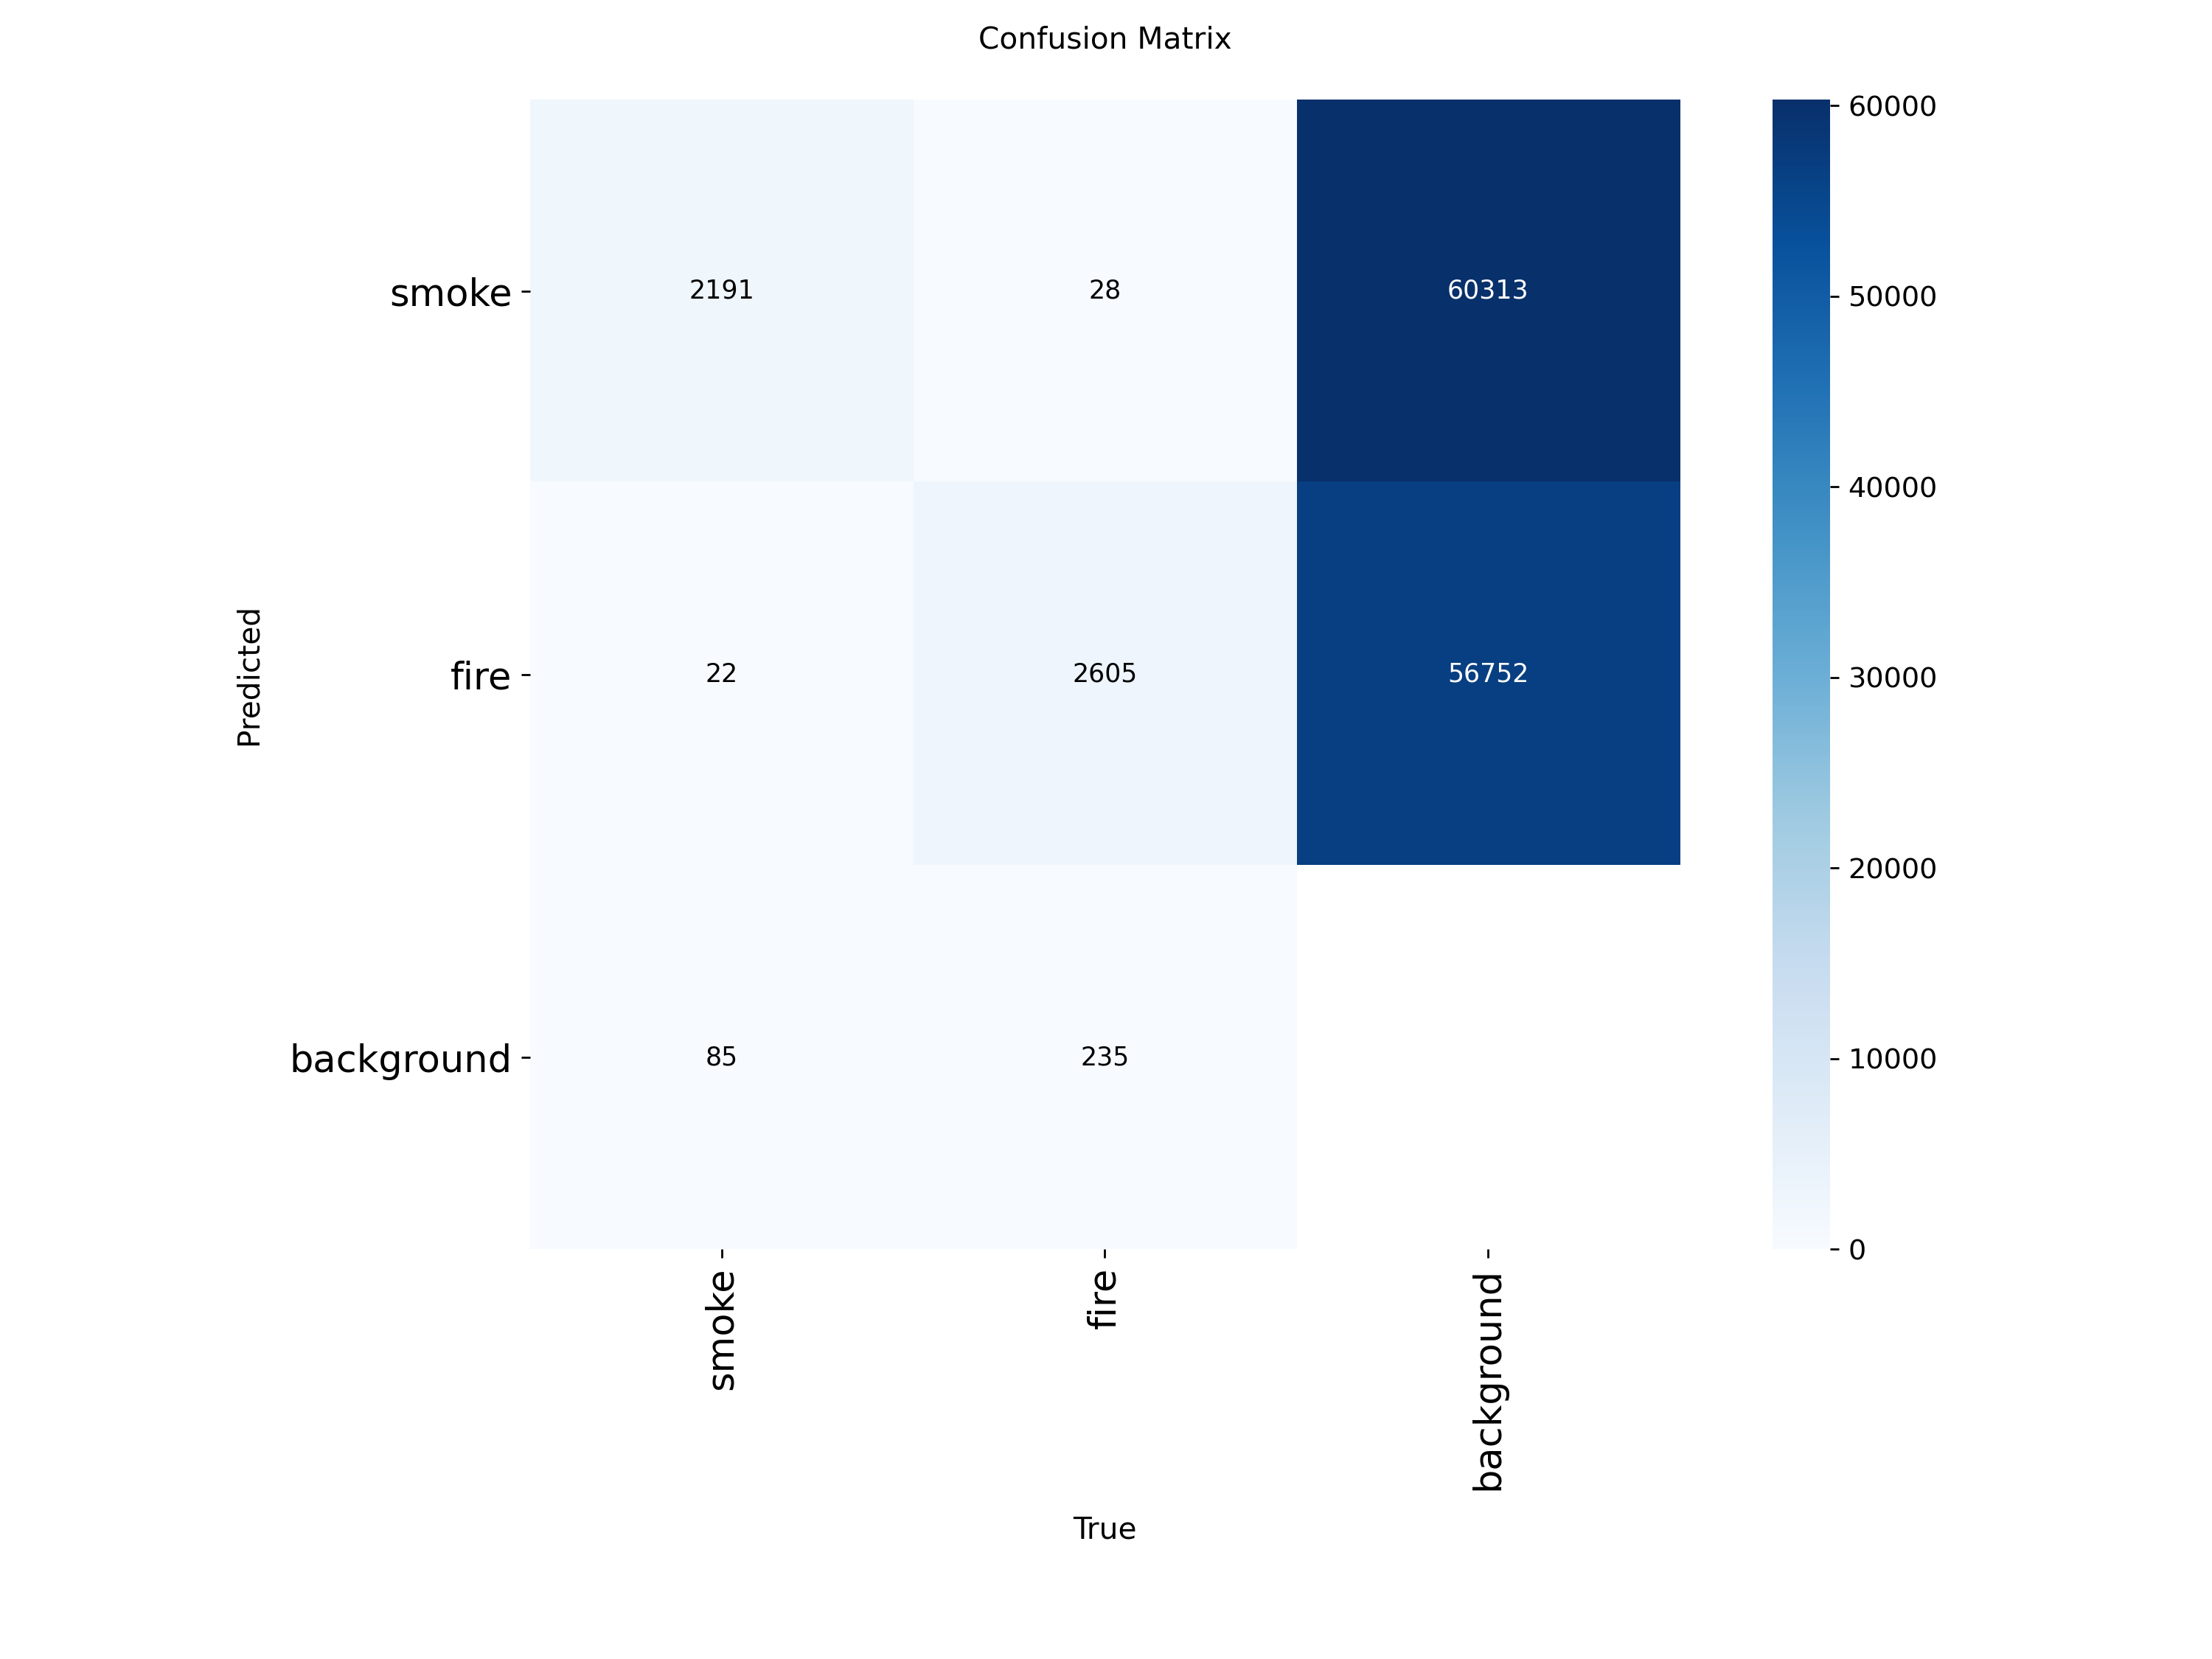

In [16]:
from IPython.display import Image, display

display(
    Image(
        filename="/content/fire_smoke_evaluation/test_results/confusion_matrix.png"
    )
)

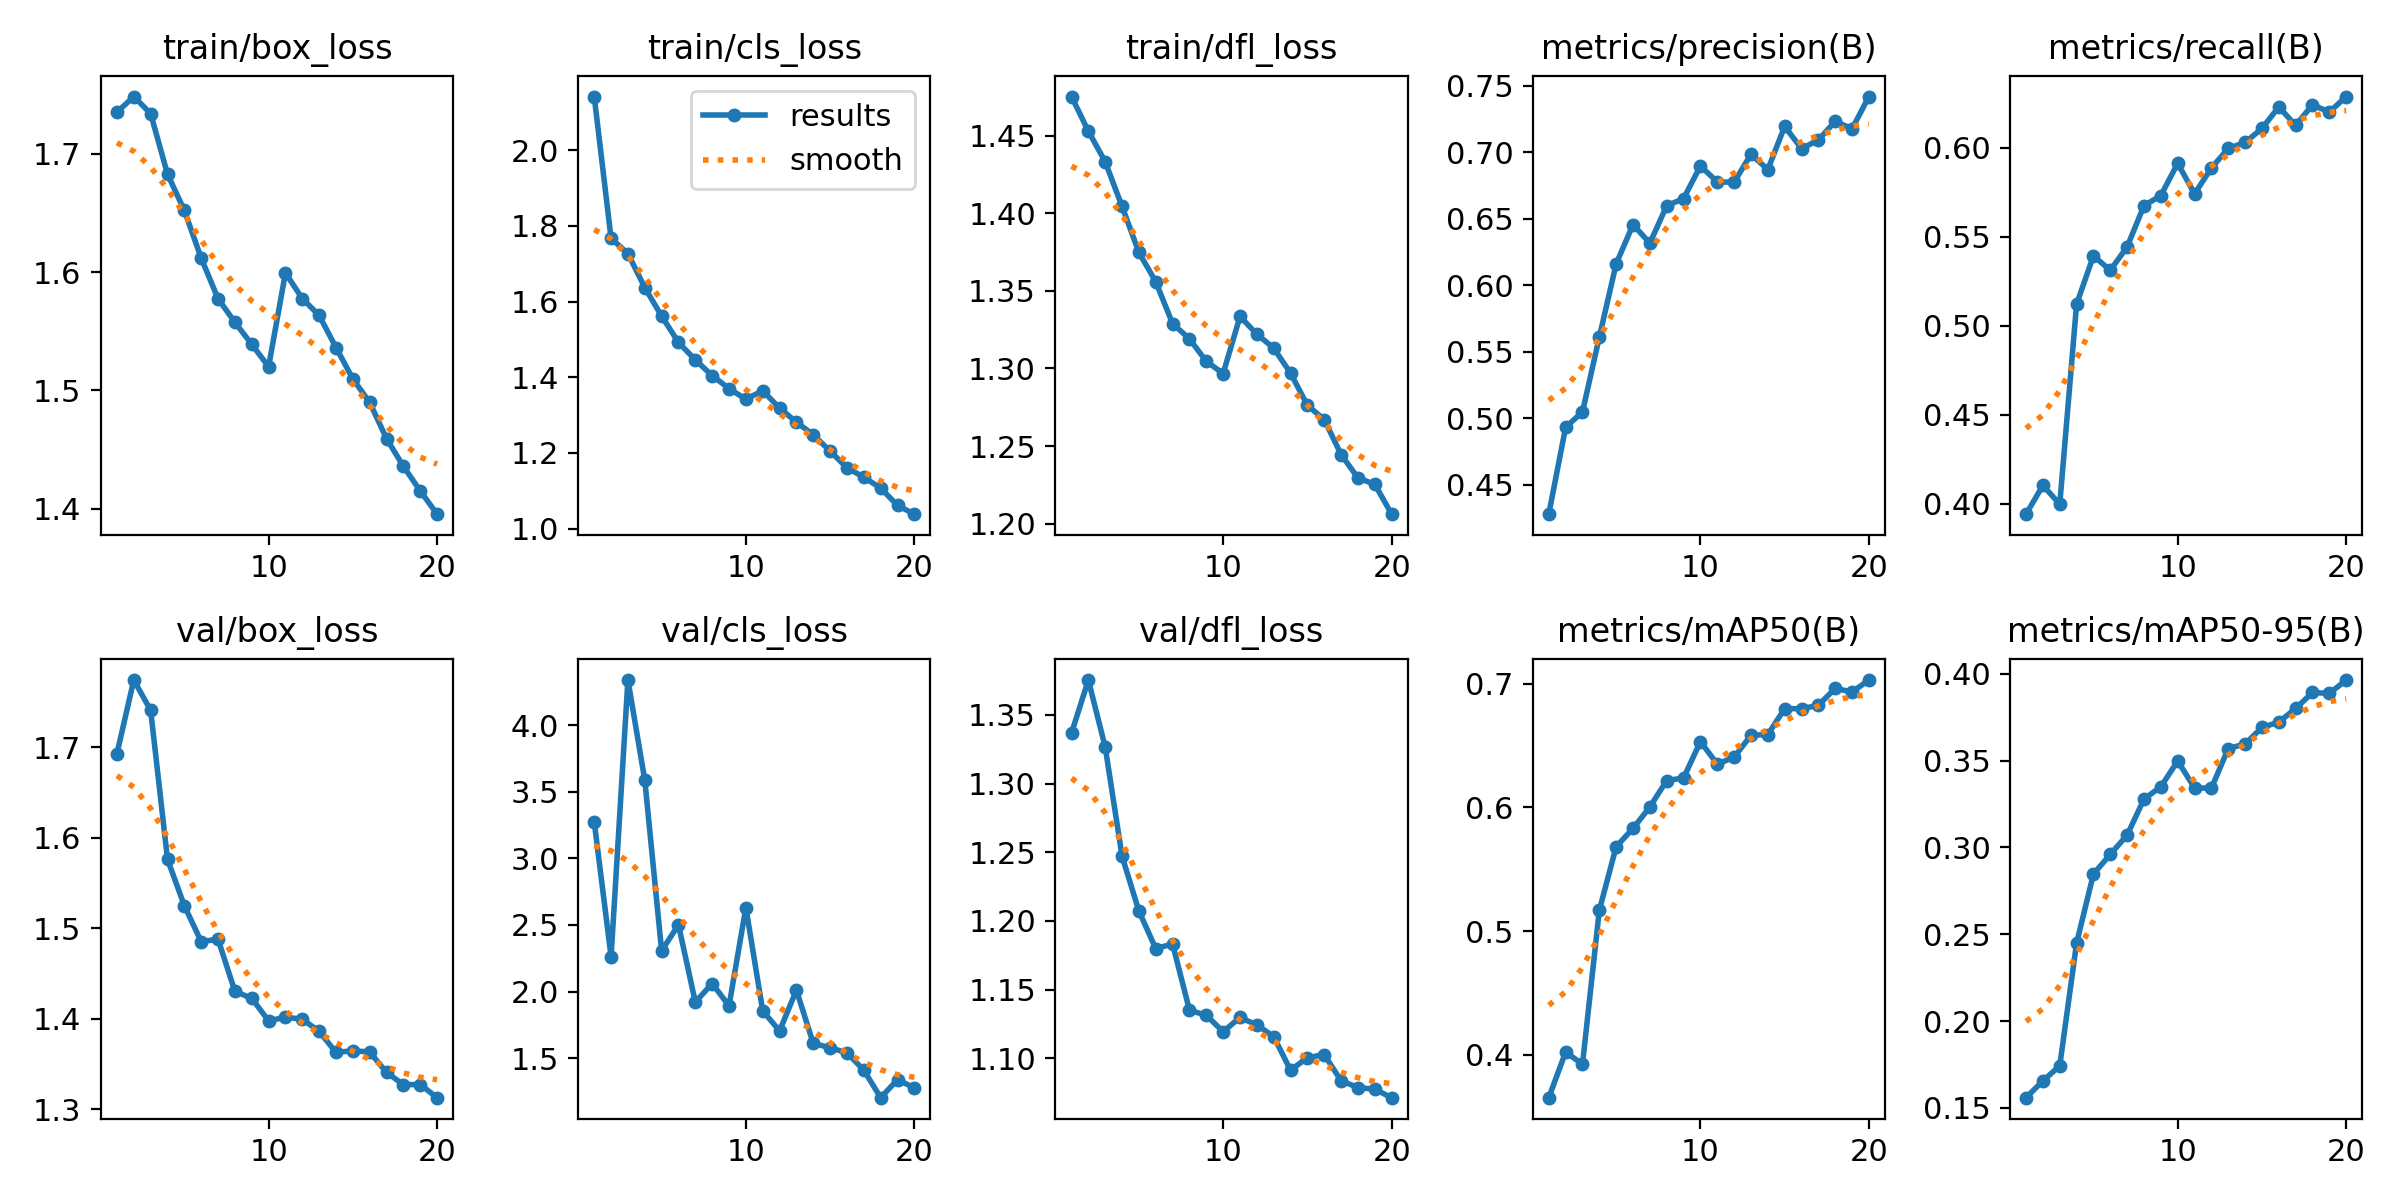

In [17]:
display(
    Image(
        filename="/content/fire_smoke_runs/fire_smoke_final/results.png"
    )
)

In [18]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

Saving House Fire Amid Billowing Smoke.png to House Fire Amid Billowing Smoke.png


In [22]:
results = best_model.predict(
    source=image_path,
    conf=0.35,
    imgsz=416,
    device=0,
    save=True
)


image 1/1 /content/House Fire Amid Billowing Smoke.png: 256x416 1 smoke, 1 fire, 7.3ms
Speed: 7.4ms preprocess, 7.3ms inference, 6.9ms postprocess per image at shape (1, 3, 256, 416)
Results saved to /content/runs/detect/predict


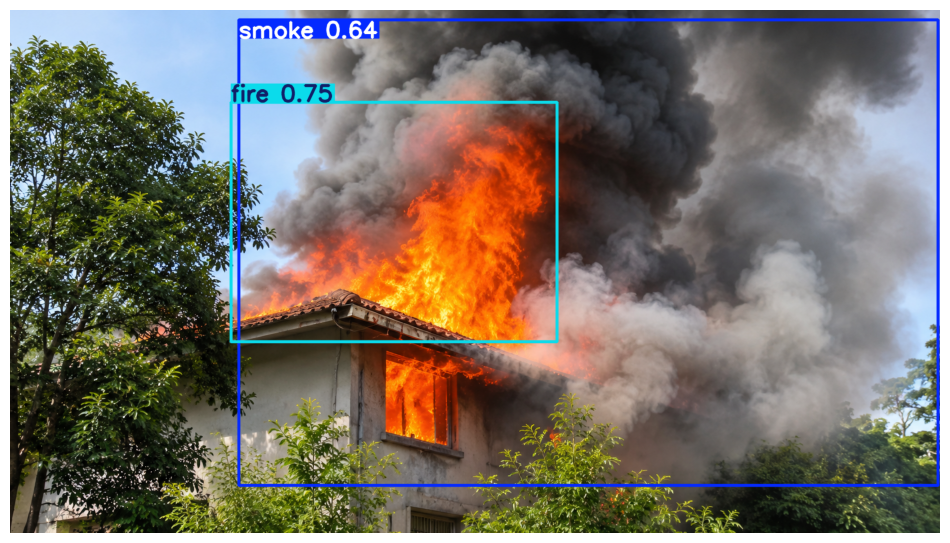

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(results[0].plot()[..., ::-1])
plt.axis("off")
plt.show()

In [25]:
import os

for root, dirs, files in os.walk("/content"):
    if "best.pt" in files:
        print("FOUND MODEL:", os.path.join(root, "best.pt"))

FOUND MODEL: /content/fire_smoke_runs/fire_smoke_final/weights/best.pt


In [26]:
from ultralytics import YOLO

model_path = "/content/fire_smoke_runs/fire_smoke_final/weights/best.pt"

model = YOLO(model_path)

print("Smoke and Fire Detection Model Loaded Successfully!")

Smoke and Fire Detection Model Loaded Successfully!


In [27]:
metrics = model.val(
    data="/content/fire_smoke.yaml",
    split="test",
    imgsz=416,
    batch=16,
    plots=True
)

print("\nFINAL MODEL PERFORMANCE")
print("-----------------------")
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 134.4±71.2 MB/s, size: 82.5 KB)
val: Scanning /kaggle/input/smoke-fire-detection-yolo/data/test/labels... 4295 images, 2005 backgrounds, 15 corrupt: 100% ━━━━━━━━━━━━ 4306/4306 447.7it/s 9.6s
val: /kaggle/input/smoke-fire-detection-yolo/data/test/images/WEB10769.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0296875]
val: /kaggle/input/smoke-fire-detection-yolo/data/test/images/WEB10775.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.015625]
val: /kaggle/input/smoke-fire-detection-yolo/data/test/images/WEB11243.jpg: ignoring corrupt image/label: [Errno 30] Read-only file system: '/kaggle/input/smoke-fire-detection-yolo/data/test/images/.WEB11243.780aeb480b8c445282ecb311814a9962.jpg'
val: /kaggle/input/smoke-

/content/runs/detect/val/confusion_matrix_normalized.png


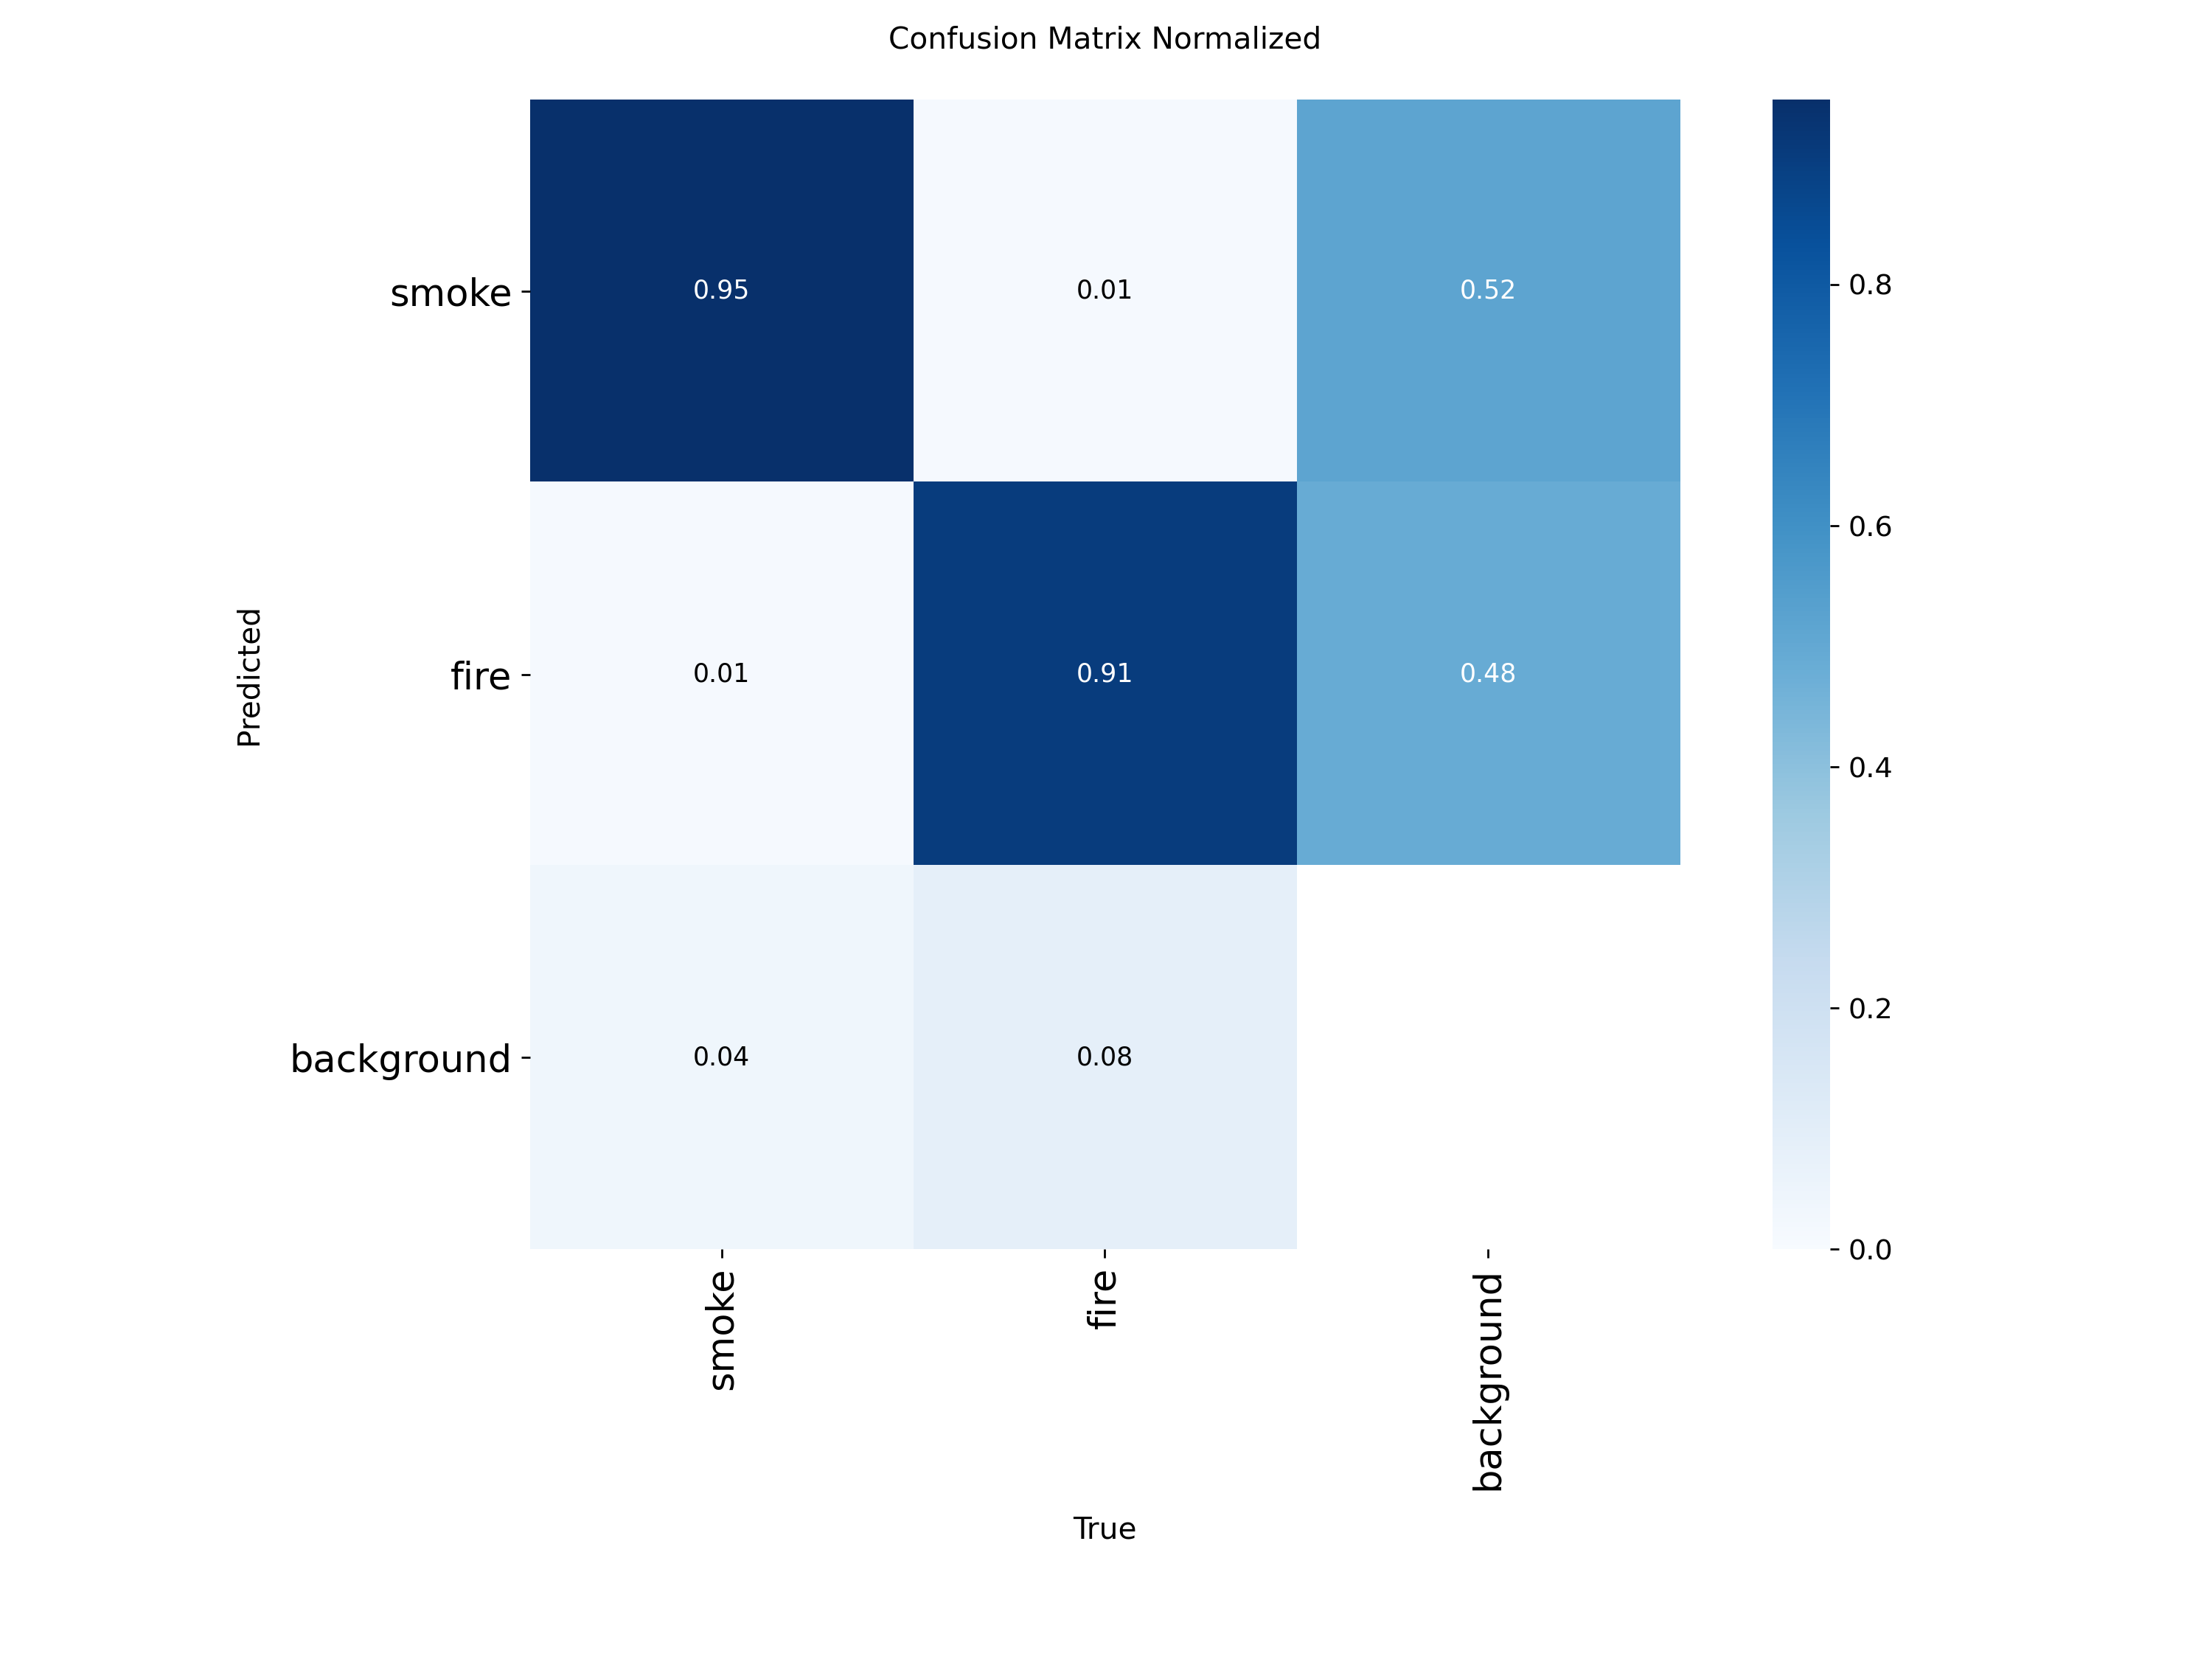

/content/runs/detect/val/confusion_matrix.png


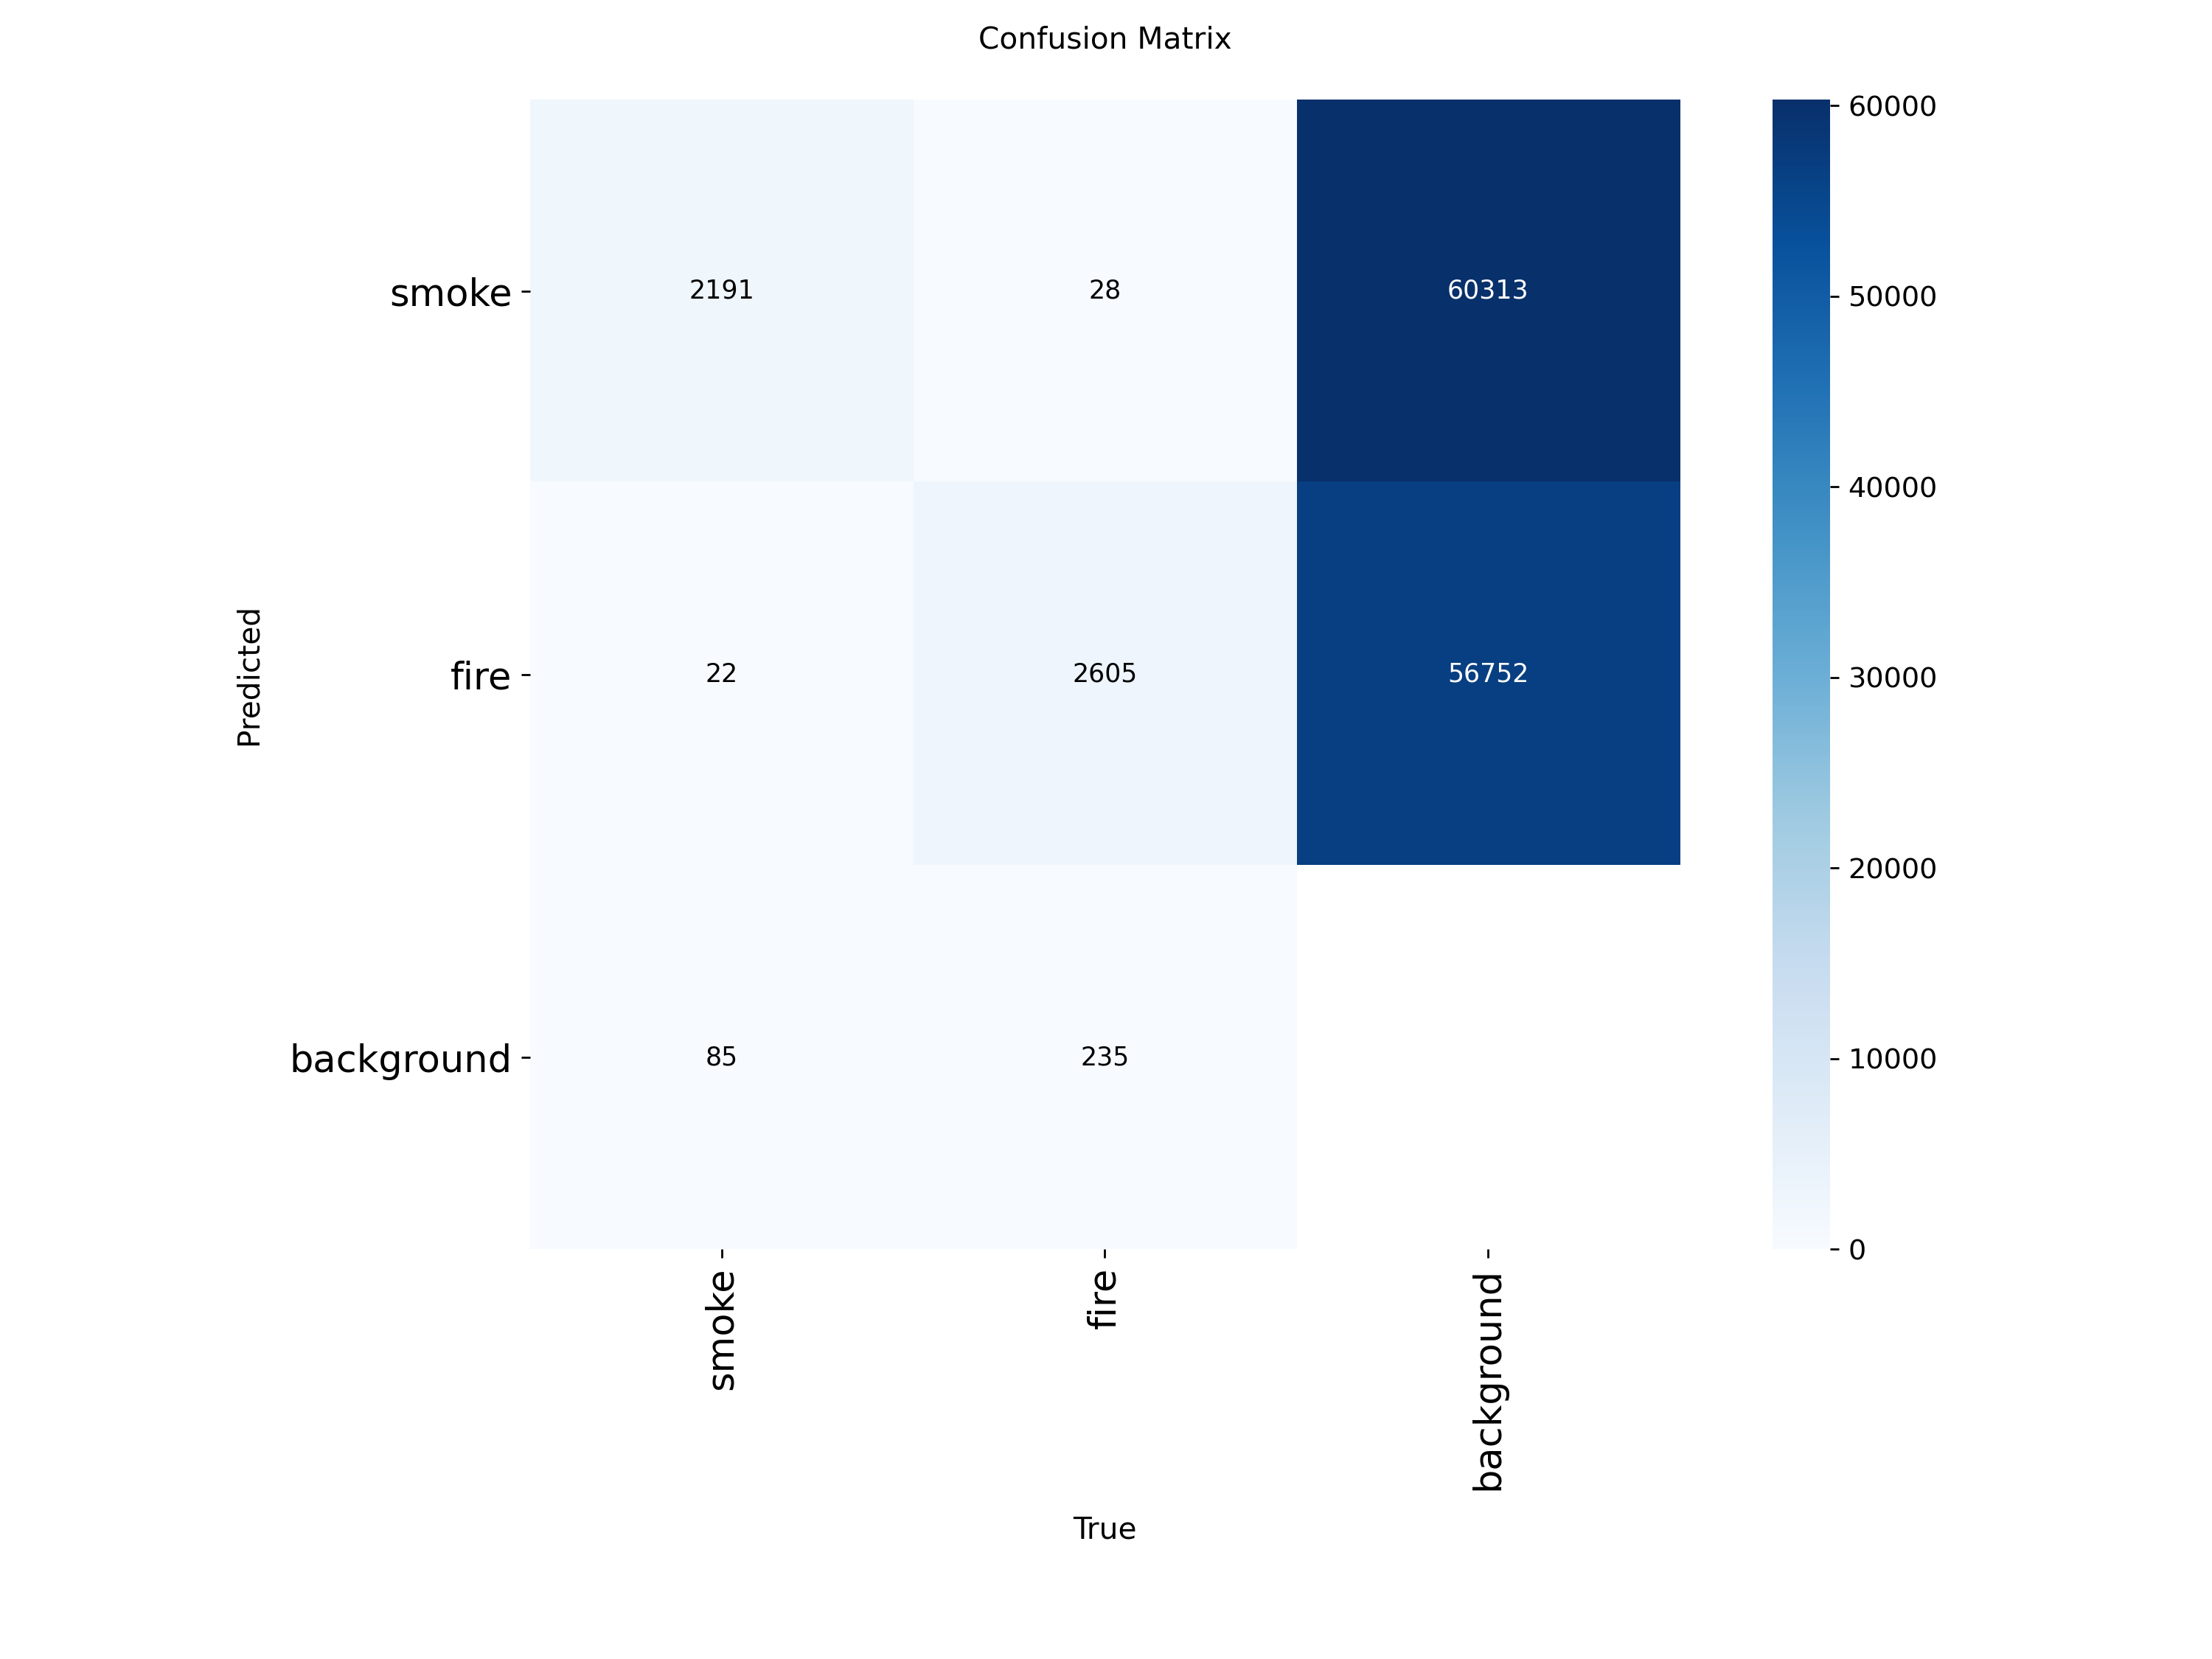

/content/runs/detect/val/BoxR_curve.png


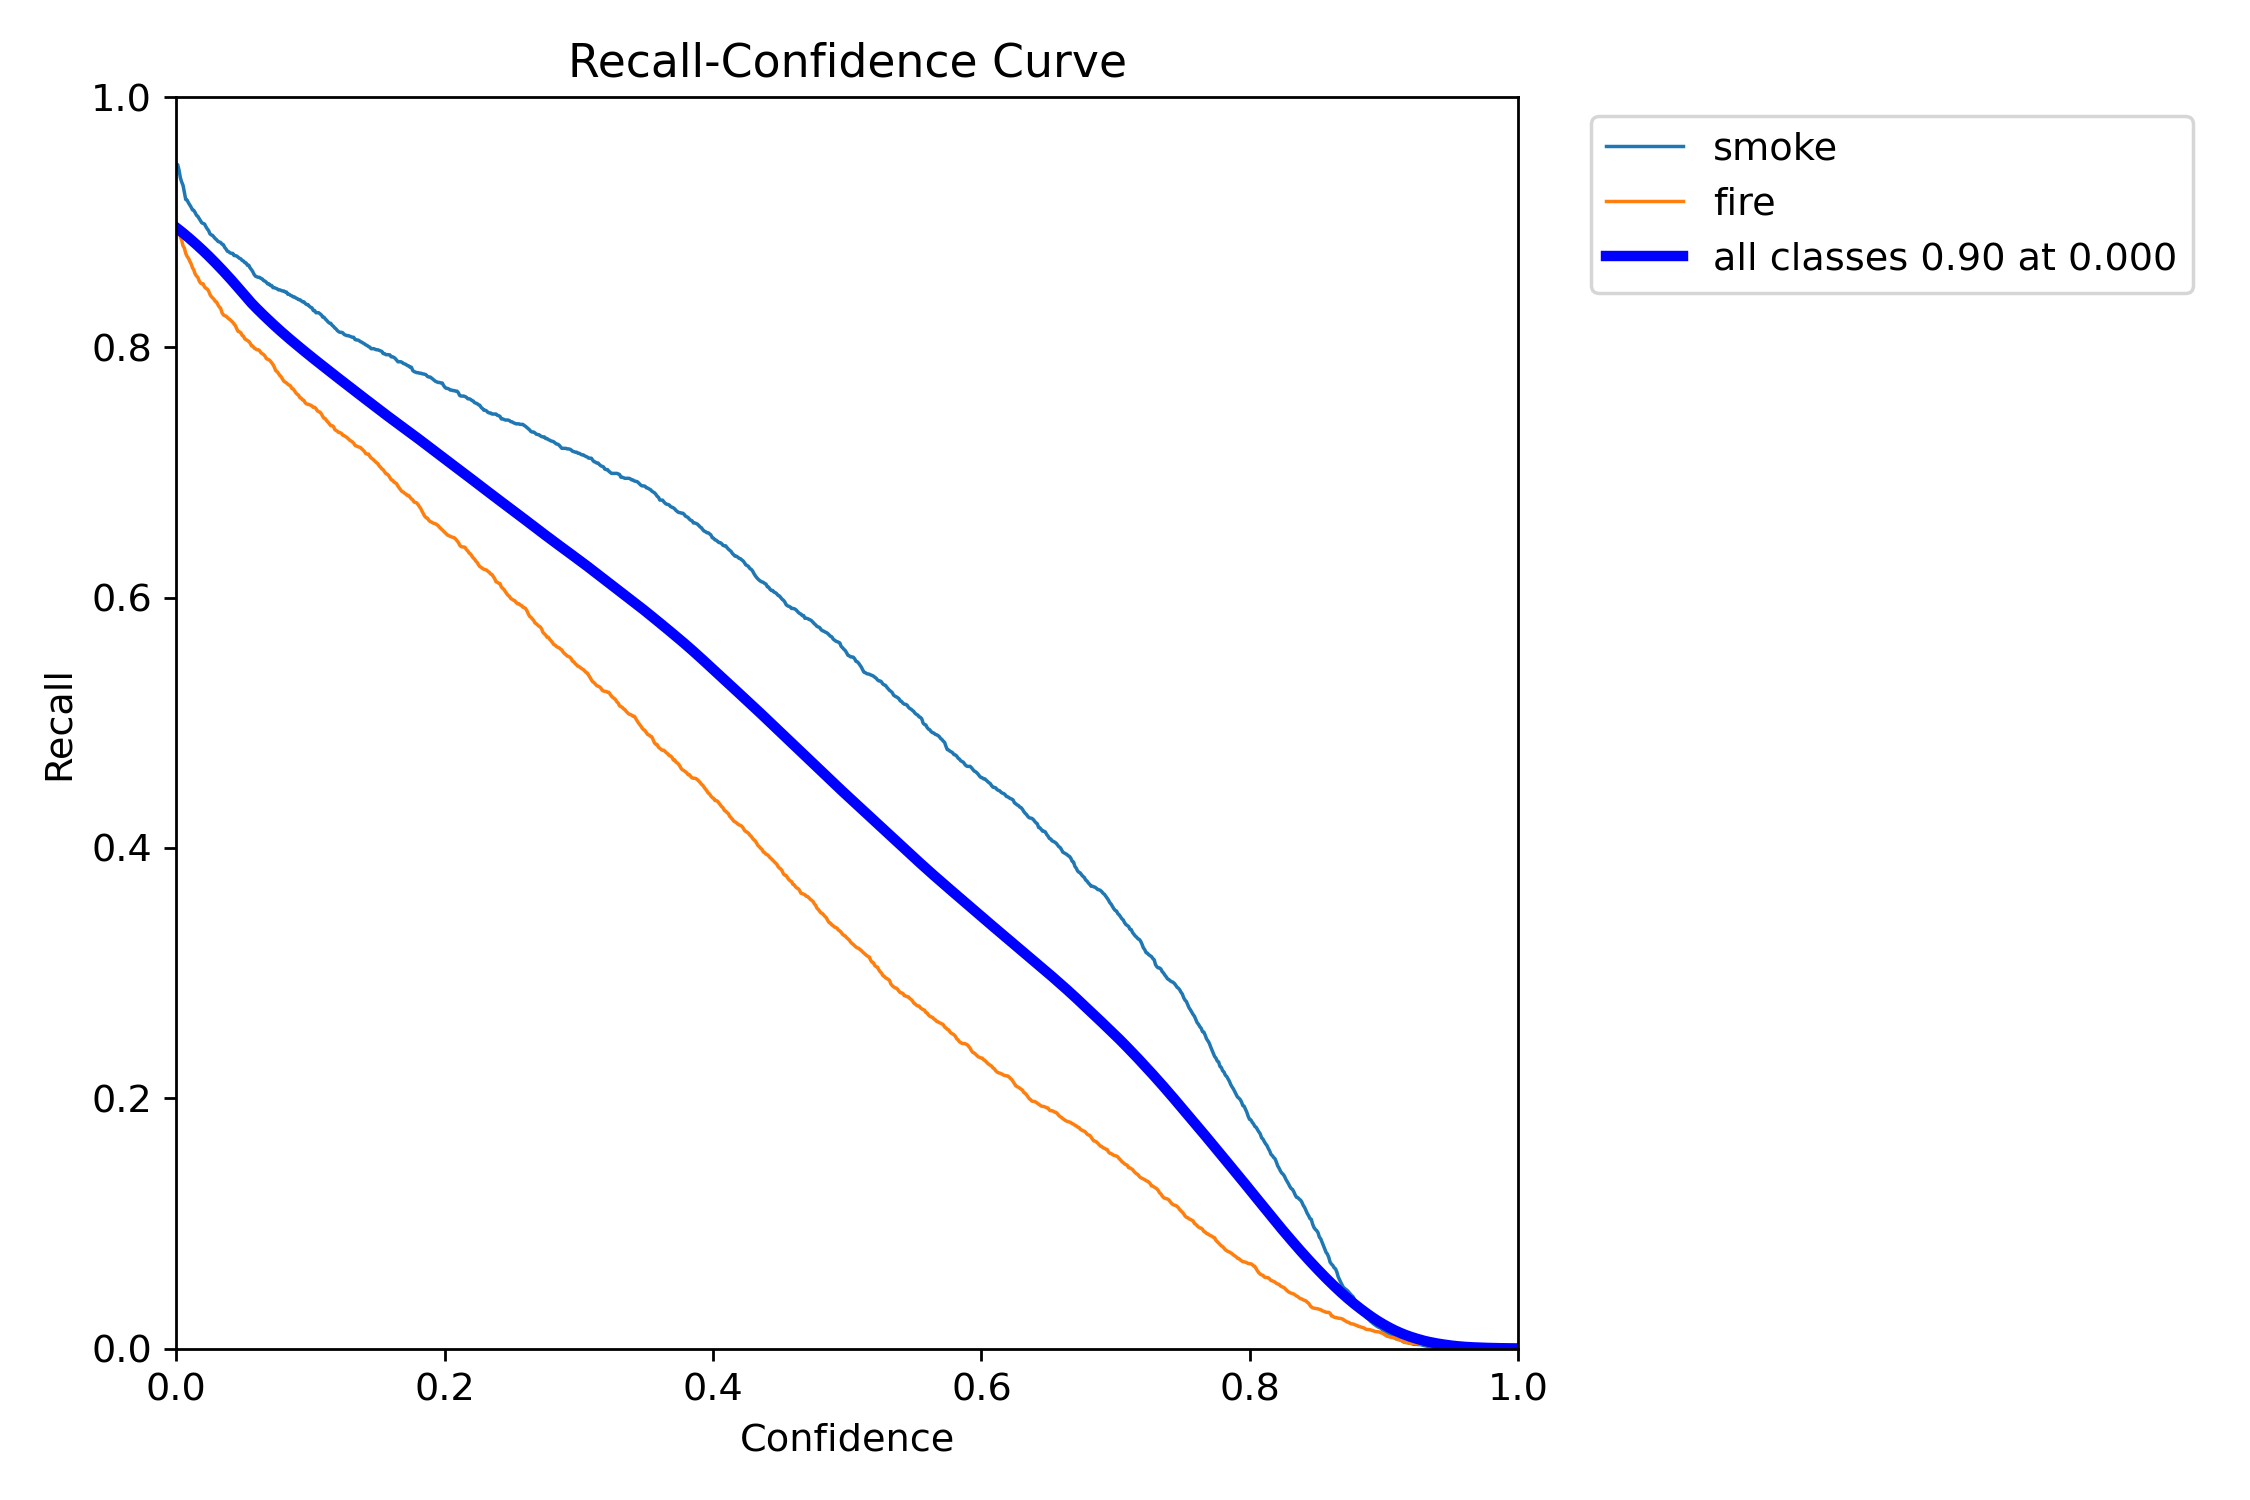

/content/runs/detect/val/BoxF1_curve.png


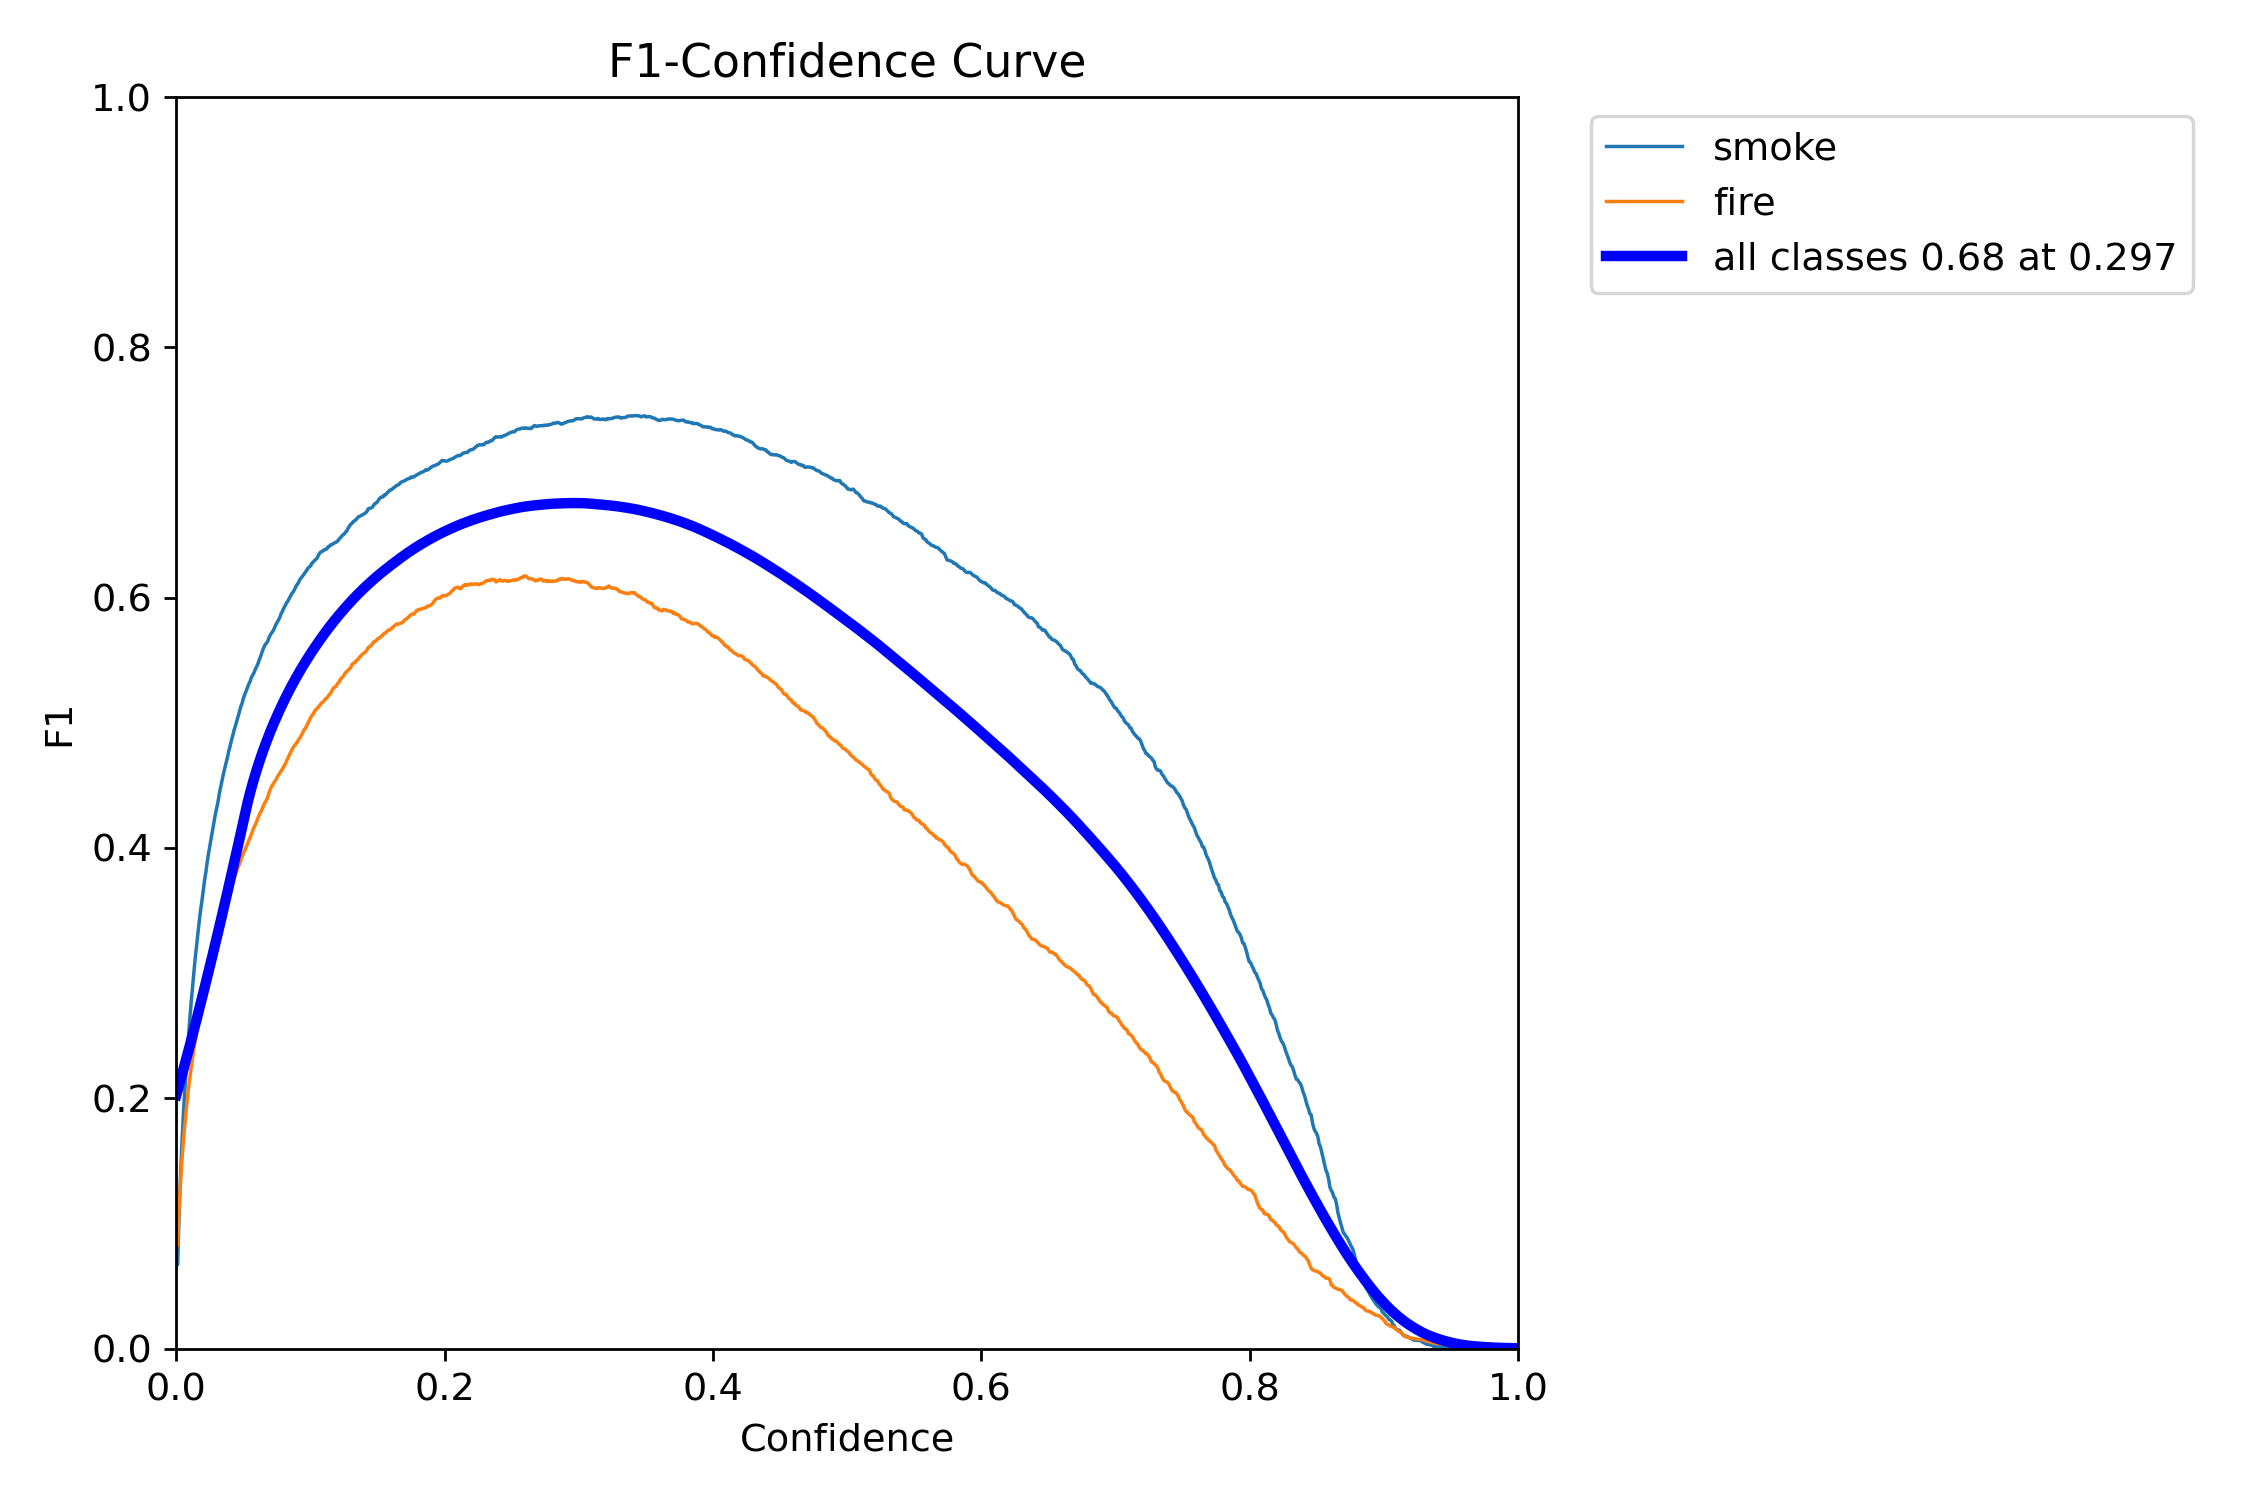

/content/runs/detect/val/BoxPR_curve.png


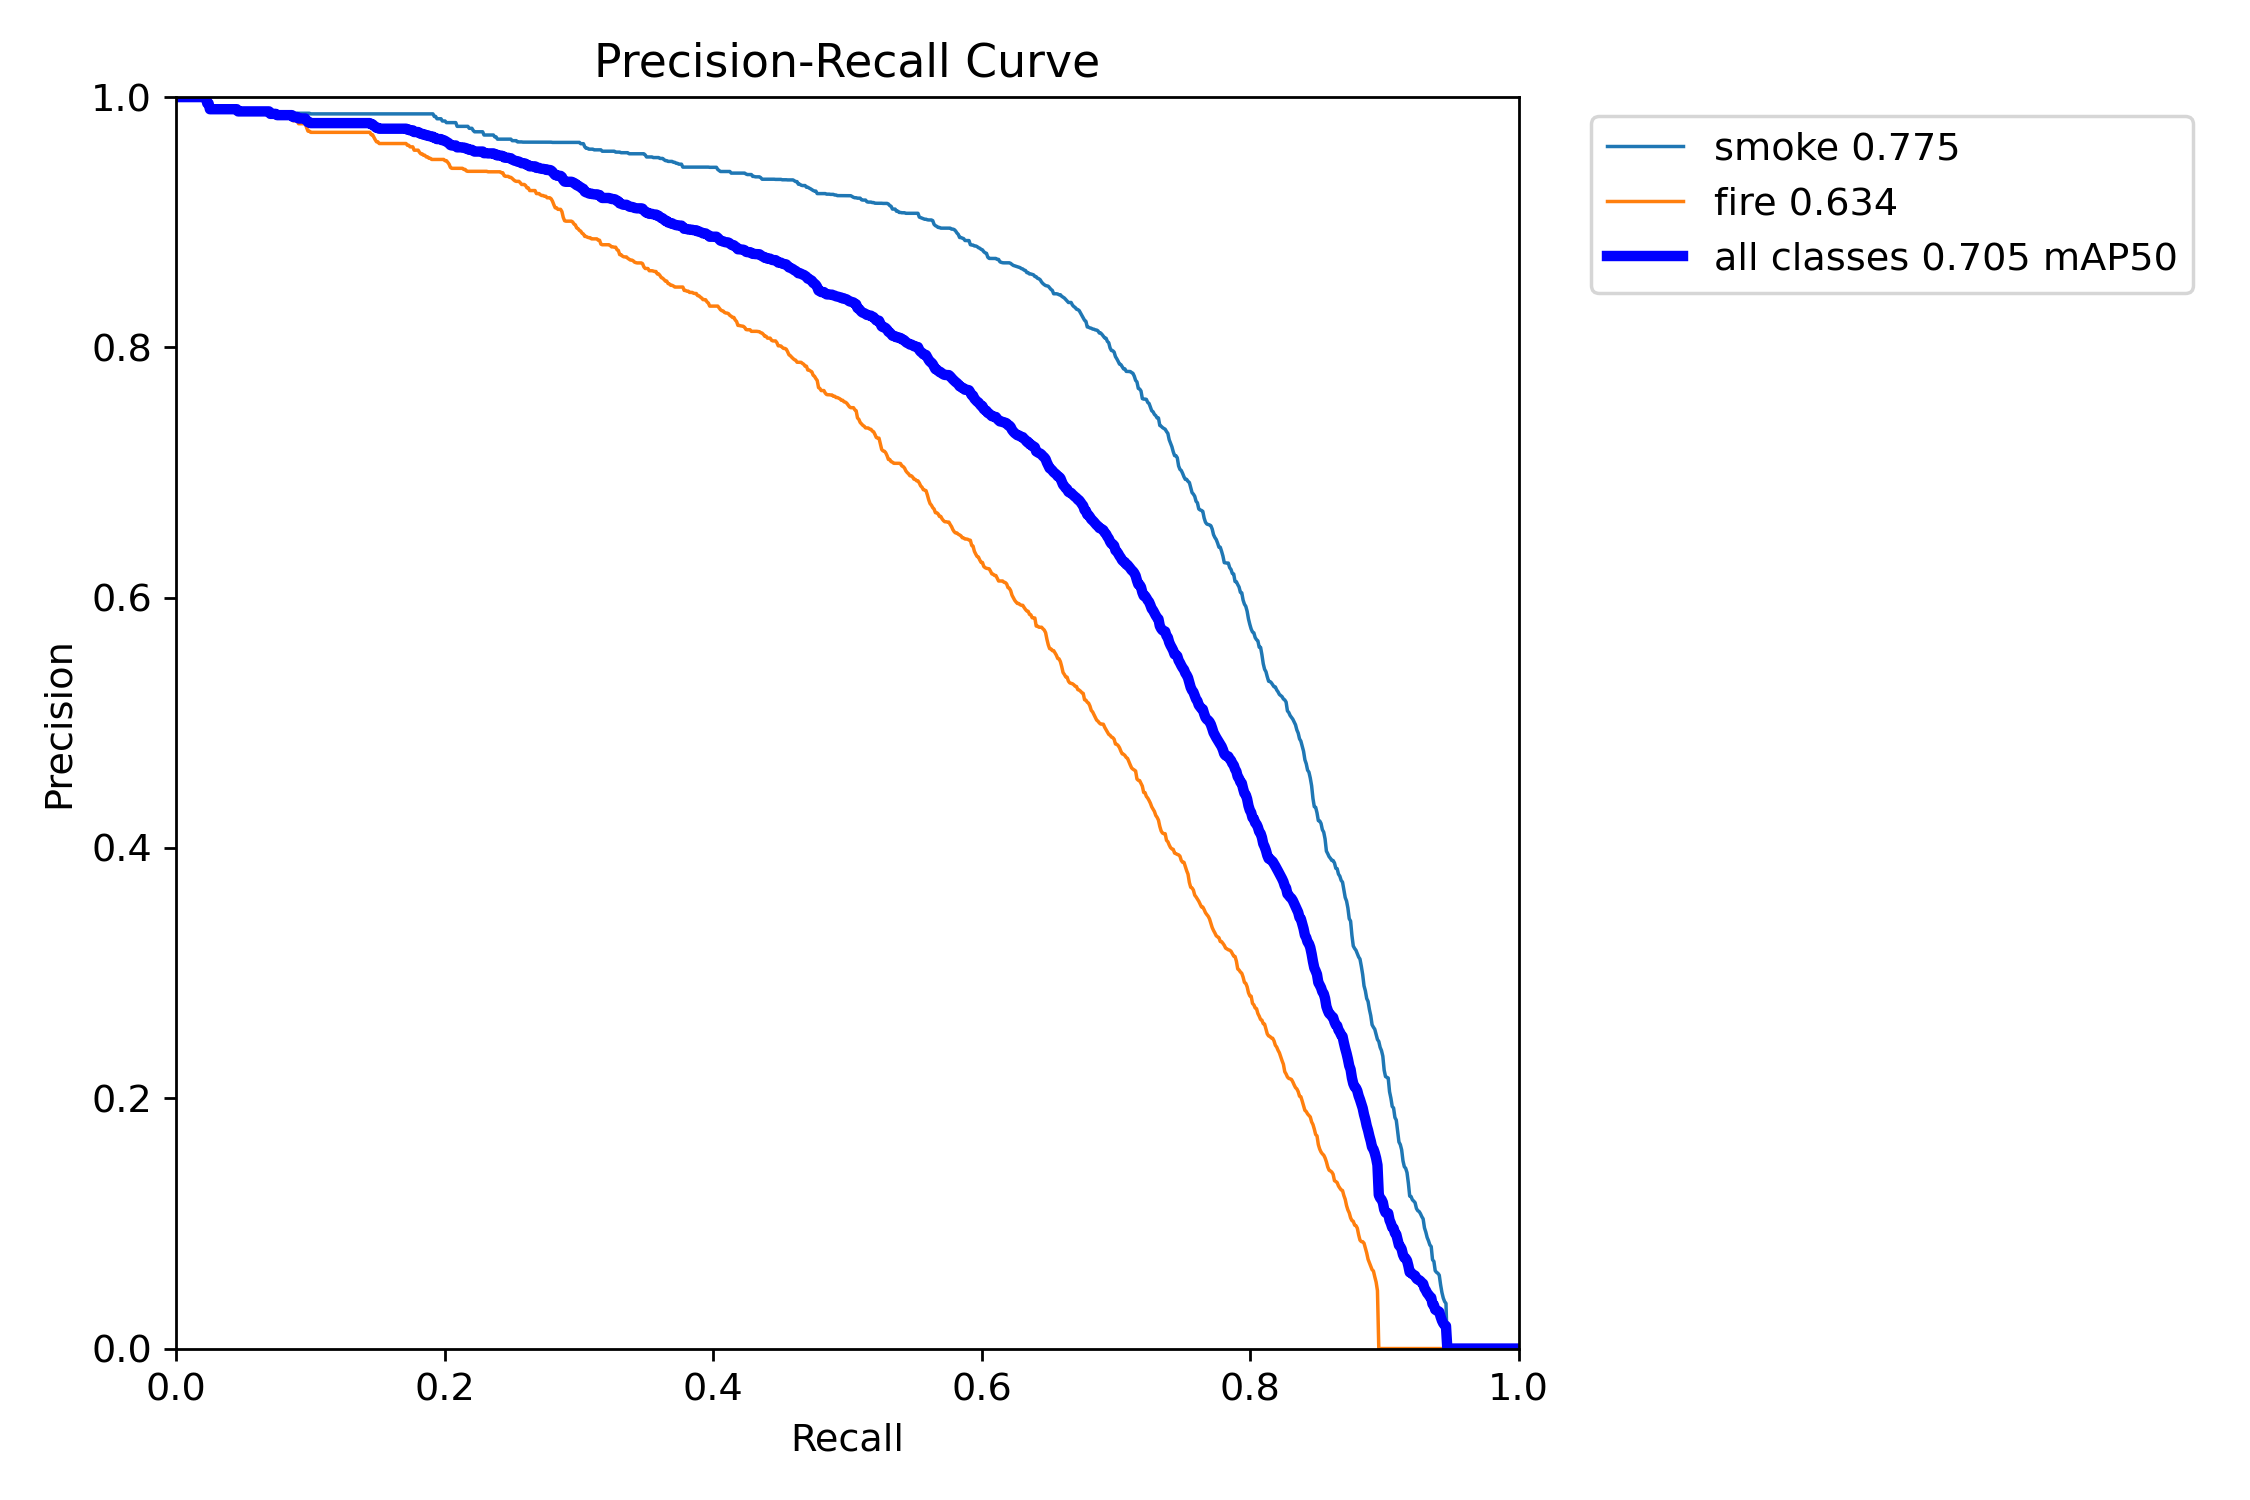

/content/runs/detect/val/BoxP_curve.png


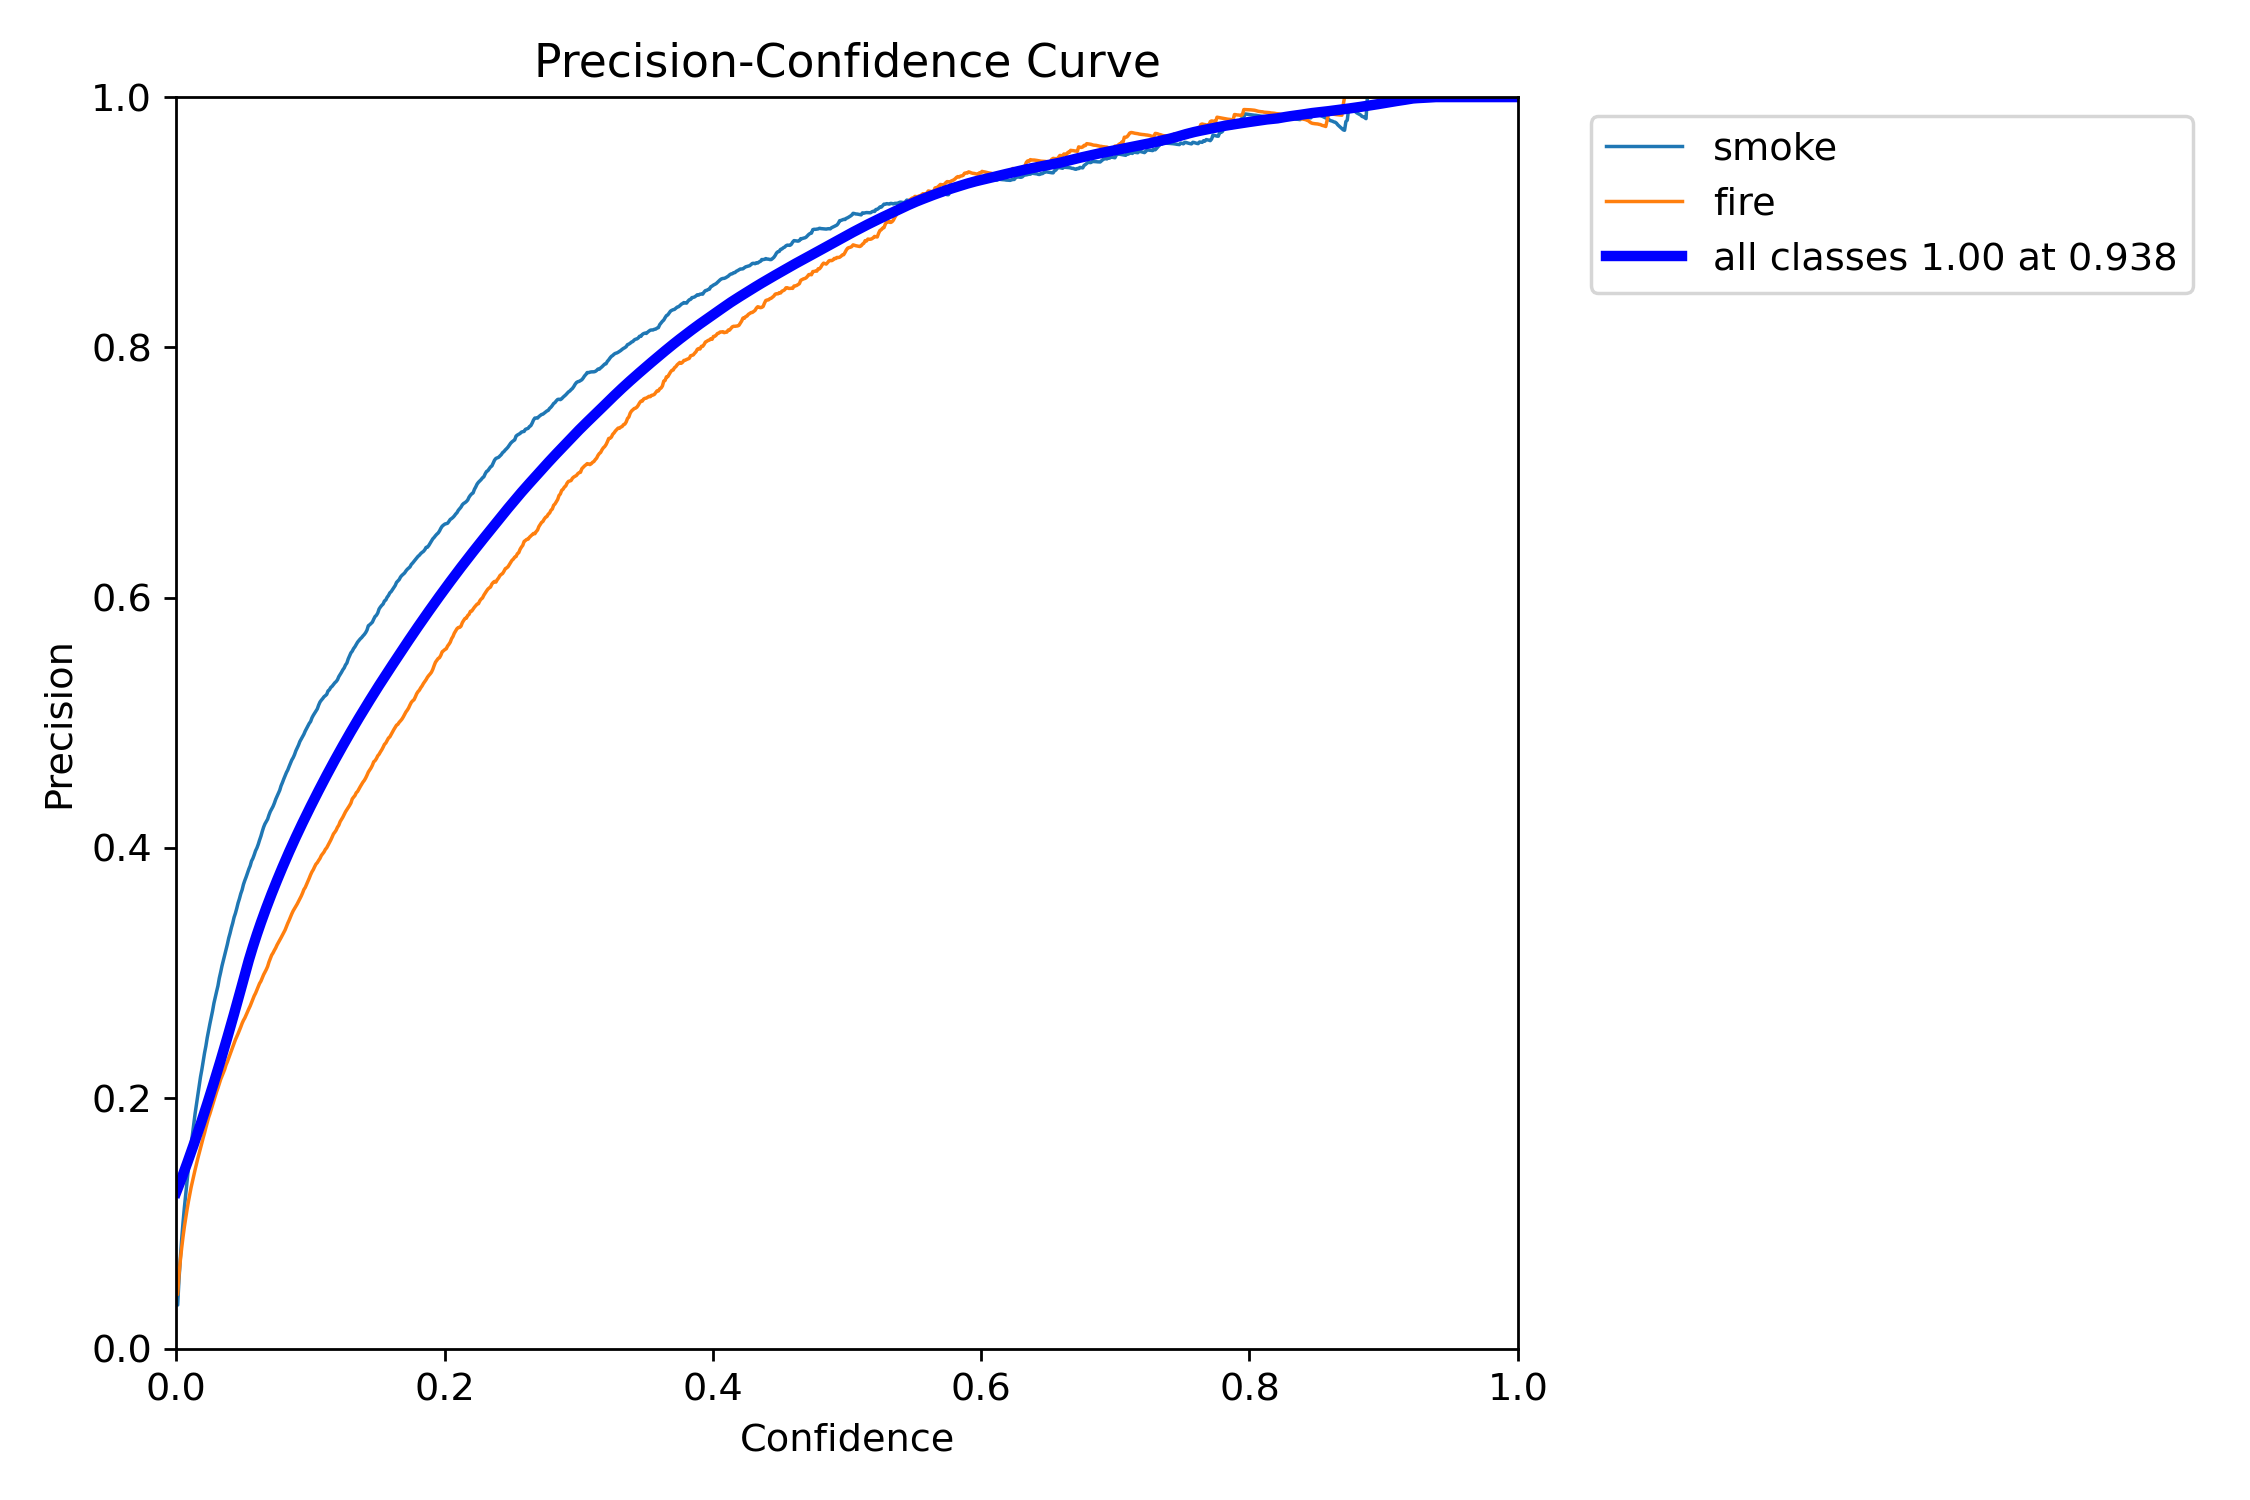

In [28]:
import glob
from IPython.display import Image, display

graphs = glob.glob("/content/runs/detect/val/*.png")

for graph in graphs:
    print(graph)
    display(Image(filename=graph))